# Step 1 — Data sources and preprocessing

First stage of the pipeline: raw INEGI microdata → per-year panels (`ch1_012`) → the concatenated
event tables and the population / marginalization intermediates (`ch1_015`).

Checked against **Section 1 of the thesis**
(`docs/Farinella_Elsa_PDM_Statistics_2024_2025_with_comments_from_olli.pdf`). Where the thesis makes
no checkable claim, the check is either internal consistency or is flagged as needing external
confirmation.

**Scope.** Inspection only — the processing happens in R. Refresh the exports first:

```bash
pixi run Rscript notebooks/export_ch1_data.R
pixi run -e py jupyter lab
```

In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP  = ROOT / "input-data-processed" / "py-export"
assert EXP.exists(), "run: pixi run Rscript notebooks/export_ch1_data.R"

pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

fert_panels = pd.read_parquet(EXP / "panel_summary_fertility.parquet")
mort_panels = pd.read_parquet(EXP / "panel_summary_mortality.parquet")
births      = pd.read_parquet(EXP / "births.parquet")
deaths      = pd.read_parquet(EXP / "deaths.parquet")
universes   = pd.read_parquet(EXP / "mun_universes.parquet")
imm         = pd.read_parquet(EXP / "imm_2020_raw.parquet")
print(f"births {len(births):,} rows | deaths {len(deaths):,} rows")

births 6,511,781 rows | deaths 1,444,216 rows


## 1. What the thesis claims

> "Fertility data: *Estadísticas de Nacimientos Registrados*. Mortality data: *Estadísticas de
> Defunciones Registradas*." — the INEGI portal provides 2017–2023; "earlier data, covering
> **registration years from 1990 onwards**, were obtained through the courtesy of José Manuel Aburto."

> Fertility processing: "Remove records with invalid or missing geographical identifiers; standardise
> municipality codes to a unified **five-digit** format." — "For female parents (mothers), keep ages
> from **15 to 64** years; for male parents (fathers), keep ages from **15 to 84** years. Classify
> ages into five-year groups."

> "Compute, for each municipality, sex, age group, and time period, the corresponding number of
> registered births." Mortality "processed following the same principles and steps".

> Population: 1990–2020 census-based, 2021–2040 projections; "we retained the period **1990–2023**".

Checkable here: the year coverage, the five-digit codes, the age windows by sex, the panel schema.
The provenance of the pre-2017 files is not checkable from the repo.

## 2. Coverage of the per-year panels

Each file holds the events **registered** in that year. Note the pipeline holds *more* than the
thesis describes: births go back to registration year 1985, and both series extend to 2024.

In [3]:
cov = pd.DataFrame({
    "fertility": {
        "files": len(fert_panels),
        "registration years": f"{fert_panels['year_reg'].min()}–{fert_panels['year_reg'].max()}",
        "total events": fert_panels["events"].sum(),
        "files storing a 2-digit occurrence year": int(fert_panels["two_digit_year"].sum()),
    },
    "mortality": {
        "files": len(mort_panels),
        "registration years": f"{mort_panels['year_reg'].min()}–{mort_panels['year_reg'].max()}",
        "total events": mort_panels["events"].sum(),
        "files storing a 2-digit occurrence year": int(mort_panels["two_digit_year"].sum()),
    },
})
print("thesis describes registration years from 1990 onwards\n")
cov

thesis describes registration years from 1990 onwards



,fertility,mortality
files,40,35
registration years,1985–2024,1990–2024
total events,181764801,11696980
files storing a 2-digit occurrence year,13,8


In [4]:
# every registration year present exactly once, no gaps
for name, p in (("fertility", fert_panels), ("mortality", mort_panels)):
    yrs = p["year_reg"].to_numpy()
    gaps = set(range(yrs.min(), yrs.max() + 1)) - set(yrs)
    print(f"{name:<10s} {yrs.min()}–{yrs.max()}  duplicates: {len(yrs) - len(set(yrs))}  gaps: {sorted(gaps) or 'none'}")

fertility  1985–2024  duplicates: 0  gaps: none
mortality  1990–2024  duplicates: 0  gaps: none


### 2b. The 2-digit occurrence year and the `99` sentinel

The early files store the occurrence year as two digits. `99` in those files is not 1999 — a death
registered in 1990 cannot have occurred in 1999 — it is the INEGI **unknown-year** code.

In [4]:
sent = pd.concat([
    fert_panels.assign(series="fertility"),
    mort_panels.assign(series="mortality"),
]).query("sentinel_rows > 0")[["series", "source", "year_reg", "sentinel_rows", "sentinel_events", "events"]]
sent["% of the file"] = 100 * sent["sentinel_events"] / sent["events"]
print(f"files carrying the sentinel: {len(sent)}   affected events: {sent['sentinel_events'].sum():,}")
sent

files carrying the sentinel: 8   affected events: 28,346


,series,source,year_reg,sentinel_rows,sentinel_events,events,% of the file
0,mortality,mort_1990.RDS,1990,4294,8465,213728,3.961
1,mortality,mort_1991.RDS,1991,3526,6205,217034,2.859
2,mortality,mort_1992.RDS,1992,3343,6696,222426,3.01
3,mortality,mort_1993.RDS,1993,3161,5866,227169,2.582
4,mortality,mort_1994.RDS,1994,302,340,229877,0.1479
5,mortality,mort_1995.RDS,1995,291,318,233788,0.136
6,mortality,mort_1996.RDS,1996,210,221,235474,0.09385
7,mortality,mort_1997.RDS,1997,220,235,240876,0.09756


**Defect found and fixed at this step.** `ch1_015` used to load the panels with its own inline loop
that mapped *every* 2-digit value as `1900 + year`, so `99` became a real occurrence year 1999. That
moved the events above into 1999 and gave them a negative registration delay (occurring in 1999,
registered in 1990–1997). `R/load_year_panels.R` — the helper `ch2_040` / `ch2_050` / `ch2_060`
already used — drops the sentinel instead. `ch1_015` now goes through that helper, so both paths
agree.

Fertility is unaffected: no `fert_*` file carries a `99`.

Verify the corrected tables carry no trace of it:

In [5]:
print("occurrence year 1999 registered before 1999 (impossible):",
      int(((deaths["year"] == 1999) & (deaths["year_reg"] < 1999)).sum()))
for name, df, col in (("births", births, "births"), ("deaths", deaths, "deaths")):
    neg = df["year_reg"] < df["year"]
    print(f"{name:<7s} rows with registration before occurrence: {int(neg.sum())}"
          f"   events: {int(df.loc[neg, col].sum())}")

occurrence year 1999 registered before 1999 (impossible): 0
births  rows with registration before occurrence: 0   events: 0
deaths  rows with registration before occurrence: 0   events: 0


### 2c. Reconciliation: panels → event tables

Every event in the per-year panels should either reach the concatenated table or be dropped for a
reason we can name. Account for the difference exactly — an unexplained residual here would mean
records are vanishing silently.

In [6]:
rec = []
for name, panels, df, col in (("births", fert_panels, births, "births"),
                              ("deaths", mort_panels, deaths, "deaths")):
    panel_total = panels["events"].sum()
    final_total = df[col].sum()
    sentinel    = panels["sentinel_events"].sum()
    rec.append({
        "series": name,
        "in the per-year panels": panel_total,
        "unknown-year sentinel (dropped)": -sentinel,
        "occurrence before 1985 (dropped)": -(panel_total - sentinel - final_total),
        "in the concatenated table": final_total,
        "unexplained": panel_total - sentinel - (panel_total - sentinel - final_total) - final_total,
    })
pd.DataFrame(rec).set_index("series").T

series,births,deaths
in the per-year panels,181764801,11696980
unknown-year sentinel (dropped),0,-28346
occurrence before 1985 (dropped),-6845057,0
in the concatenated table,174919744,11668634
unexplained,0,0


The births line is the one to be aware of: **6,845,057 births (3.8%)** have an occurrence year before
1985 — late birth registration, going back to occurrence year 1901 — and `ch2_060` removes them with
`filter(year >= 1985, year <= 2024)`.

That is defensible for this study (nothing needs fertility before 1985), but it is *not* a neutral
filter: it removes precisely the longest-delay records, and Chapters 3–4 are about the delay
distribution. Anyone quoting a delay statistic should know these were cut first.

## 3. Age classification vs the thesis

The thesis keeps mothers 15–64 and fathers 15–84, in five-year bands. `R/preprocess_fertility.R`
filters exactly those windows — check what actually survives in the data:

In [8]:
band = (births.groupby(["sex", "age"], observed=True)["births"].sum()
              .unstack("sex").fillna(0).astype(int))
band["female %"] = 100 * band["female"] / band["female"].sum()
band["male %"]   = 100 * band["male"]   / band["male"].sum()
band

sex,female,male,female %,male %
age,,,,
15-19,15318589,5146587,16.84,6.13
20-24,27901428,20473926,30.67,24.39
25-29,23299345,22669645,25.61,27
30-34,14920651,17223588,16.4,20.51
35-39,7233821,10125384,7.952,12.06
40-44,1978709,4840252,2.175,5.765
45-49,256310,2055970,0.2818,2.449
50-54,54410,810836,0.05982,0.9658
55-59,0,481732,0,0.5738


In [9]:
present = {s: sorted(births.loc[births["sex"] == s].groupby("age", observed=True)["births"].sum()
                           .loc[lambda x: x > 0].index) for s in ("female", "male")}
print("mothers — thesis window 15–64, bands with any births:", present["female"])
print("fathers — thesis window 15–84, bands with any births:", present["male"])

mothers — thesis window 15–64, bands with any births: ['15-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54']
fathers — thesis window 15–84, bands with any births: ['15-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84']


Fathers span the full 15–84 window. Mothers stop at **50–54**: That is because inegi just treats 50+ as one group.

Deaths are stratified differently — they are all-age, with `age = NA` a deliberate category for INEGI
codes 4998/4999 (age unknown):

In [10]:
da = deaths.groupby("age", observed=True, dropna=False)["deaths"].sum()
print(f"death age bands: {len(da)}   total deaths {da.sum():,}")
print(f"deaths with unknown age (age = NA): {da.get(np.nan, 0):,} "
      f"({100 * da.get(np.nan, 0) / da.sum():.3f}%)")
print("\nNOTE: these rows have no population to join to. Drop them before any age standardisation.")

death age bands: 15   total deaths 11,668,634
deaths with unknown age (age = NA): 65,163 (0.558%)

NOTE: these rows have no population to join to. Drop them before any age standardisation.


## 4. Sex semantics for births

For births, `sex` is the **parent's** sex, not the baby's: every birth is recorded twice, once on the
mother's row and once on the father's. So `sum(births)` is roughly double the true count, and the
mother rows are the meaningful figure.

The ratio is below 1 because paternal age is missing more often than maternal age:

In [11]:
by_sex = births.groupby("sex", observed=True)["births"].sum()
print(by_sex.map("{:,.0f}".format).to_string())
print(f"\nmale / female = {by_sex['male'] / by_sex['female']:.4f}")
print(f"=> {1 - by_sex['male'] / by_sex['female']:.1%} of births have no usable father age")
print(f"\ntotal births on mother rows, 1985-2024: {by_sex['female']:,.0f}")

sex
female    90,963,263
male      83,956,481

male / female = 0.9230
=> 7.7% of births have no usable father age

total births on mother rows, 1985-2024: 90,963,263


## 5. Municipality identifiers

Five-digit `state(2) + municipality(3)`, zero-padded. Three sources define "the municipalities of
Mexico" and they disagree — none of them is authoritative on its own, so the overlap is what matters:

In [12]:
u = {s: set(g["mun"]) for s, g in universes.groupby("source")}
for s, v in u.items():
    print(f"{s:<34s} {len(v):>5d}")
keys = list(u)
print("\npairwise:")
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        a, b = u[keys[i]], u[keys[j]]
        print(f"  {keys[i][:22]:<24s} vs {keys[j][:22]:<24s} shared {len(a & b):>5d}"
              f"  only-left {len(a - b):>3d}  only-right {len(b - a):>3d}")

GADM 4.1 polygons                   2457
geo_info (CONAPO IMM 2020)          2457
population (CONAPO projections)     2475

pairwise:
  GADM 4.1 polygons        vs geo_info (CONAPO IMM 2   shared  2457  only-left   0  only-right   0
  GADM 4.1 polygons        vs population (CONAPO pro   shared  2457  only-left   0  only-right  18
  geo_info (CONAPO IMM 2   vs population (CONAPO pro   shared  2457  only-left   0  only-right  18


In [13]:
known = set().union(*u.values())
for name, df, col in (("births", births, "births"), ("deaths", deaths, "deaths")):
    mun = df["mun"].astype(str)
    print(f"{name:<7s} distinct mun {mun.nunique():>5d} | wrong length {(mun.str.len() != 5).sum()}"
          f" | non-numeric {(~mun.str.fullmatch(r'[0-9]{5}')).sum()}"
          f" | state codes {mun.str[:2].min()}–{mun.str[:2].max()}")
    orphan = sorted(set(mun) - known)
    ev = df.loc[mun.isin(orphan), col].sum()
    print(f"{'':<7s} codes in no municipality universe: {orphan} -> {ev:,} events "
          f"({100 * ev / df[col].sum():.4f}%)")

births  distinct mun  2478 | wrong length 0 | non-numeric 0 | state codes 01–32


        codes in no municipality universe: ['24059', '25019', '25020'] -> 619 events (0.0004%)
deaths  distinct mun  2478 | wrong length 0 | non-numeric 0 | state codes 01–32


        codes in no municipality universe: ['24059', '25019', '25020'] -> 236 events (0.0020%)


Those codes match no municipality in any source, so they can never join a population or a
`group_id`. They are the origin of the `group_id = NA` rows that appear in the grouped panels
downstream — filter them explicitly, or they surface in figures as a spurious category.

The 18 municipalities present in the CONAPO projections but absent from GADM are the opposite case:
population with no polygon. They are excluded from the aggregation by construction (`ch2_010` joins
onto the 2,457 polygons), which is why the grouping's national total is 127.8M rather than 128.2M.

## 6. Annual national totals

These are the numbers to check against INEGI's published series — the repo has nothing to validate
them against, so this table is for external confirmation (Olli, or INEGI's
*Natalidad* / *Mortalidad* tabulados).

Counted by **registration** year, which is what INEGI publishes; the occurrence-year series differs
by the registration delay.

,births (mother rows),births (all rows),deaths
year_reg,,,
1990,2404612,4679060,205263
1995,2524688,4885470,233470
2000,2534086,4880908,244610
2005,2396039,4589402,280339
2010,2494635,4774203,341211
2015,2263299,4323295,375731
2019,2018916,3848292,432783
2020,1552515,2967716,686442
2021,1799014,3432673,702879


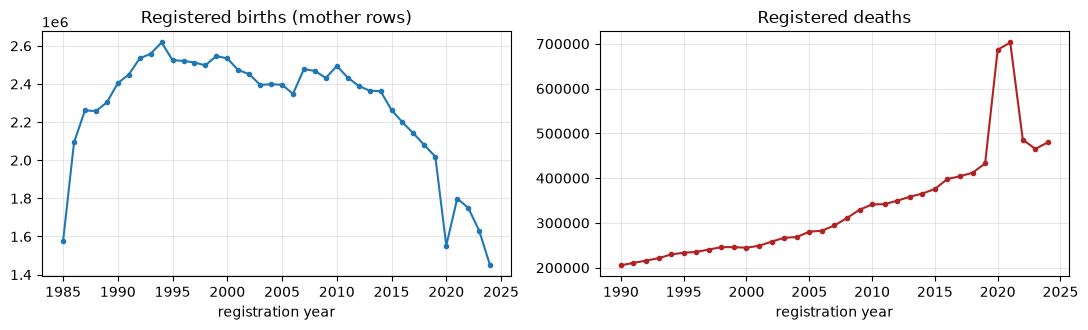

In [14]:
tot = pd.DataFrame({
    "births (mother rows)": births.query("sex == 'female'").groupby("year_reg")["births"].sum(),
    "births (all rows)":    births.groupby("year_reg")["births"].sum(),
    "deaths":               deaths.groupby("year_reg")["deaths"].sum(),
}).astype("Int64")
display(tot.loc[[1990, 1995, 2000, 2005, 2010, 2015, 2019, 2020, 2021, 2022, 2023, 2024]])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
tot["births (mother rows)"].plot(ax=ax[0], marker=".", title="Registered births (mother rows)")
tot["deaths"].plot(ax=ax[1], marker=".", color="firebrick", title="Registered deaths")
for a in ax:
    a.set_xlabel("registration year"); a.grid(alpha=.3)
plt.tight_layout()

The 2020–2021 mortality spike (COVID) and the 2024 drop-off (a year still being registered) are the
two features to expect. A 2024 that looks incomplete is not a bug — it is exactly the registration
delay Chapters 3 and 4 model.

## 7. Marginalization index — check the sign convention

CONAPO's `IMN` runs **backwards**: a higher value means *less* marginalized. Verify against a raw
deprivation indicator in the same workbook (`ANALF` = % illiterate) rather than trusting the name:

In [15]:
d = imm[imm["CVE_MUN"].notna()].copy()
for c in ("ANALF", "SBASC", "OVSDE", "PO2SM", "IMN_2020", "POB_TOT"):
    d[c] = pd.to_numeric(d[c], errors="coerce")
d = d.dropna(subset=["IMN_2020"])

print(f"municipalities with an IMN: {len(d)}")
print("\ncorrelation of IMN_2020 with deprivation indicators:")
for c, label in (("ANALF", "% illiterate"), ("SBASC", "% without basic schooling"),
                 ("OVSDE", "% dwellings without drainage"), ("PO2SM", "% earning <2 minimum wages")):
    print(f"  {label:<34s} {d['IMN_2020'].corr(d[c]):+.3f}")
print("\nNEGATIVE correlations confirm: higher IMN = LESS marginalized.")
print("So a negative coefficient on IMN means 'more marginalized -> higher outcome'.")
print("GM (the categorical grade) is correctly oriented and is the safer variable:")
print(d.groupby("GM_2020")["ANALF"].mean().sort_values().to_string())

municipalities with an IMN: 2469

correlation of IMN_2020 with deprivation indicators:
  % illiterate                       -0.848
  % without basic schooling          -0.769
  % dwellings without drainage       -0.566
  % earning <2 minimum wages         -0.699

NEGATIVE correlations confirm: higher IMN = LESS marginalized.
So a negative coefficient on IMN means 'more marginalized -> higher outcome'.
GM (the categorical grade) is correctly oriented and is the safer variable:
GM_2020
Muy bajo   3.321
Bajo       6.545
Medio      9.982
Alto       16.24
Muy alto   24.54


## 8. Population totals

The workbook's national row gives the 2020 census count; the municipal projections give a slightly
different 2020 total. Both are legitimate, and which one belongs in a denominator is a decision for
the researchers — but they must not be mixed silently.

In [16]:
nat = pd.to_numeric(imm.loc[imm["NOM_ENT"].isna() & imm["CVE_ENT"].eq("Nacional"), "POB_TOT"],
                    errors="coerce").iloc[0]
pop_full = pd.read_parquet(EXP / "population_full.parquet")
proj2020 = pop_full.query("year == 2020")["population"].sum()
print(f"IMM 2020 workbook, national row (2020 census)     : {nat:,.0f}")
print(f"CONAPO municipal projections, 2020, all ages      : {proj2020:,.0f}")
print(f"difference                                        : {proj2020 - nat:,.0f} "
      f"({100 * (proj2020 - nat) / nat:+.2f}%)")
print(f"\nch2_010 sizes the aggregation units with the projections figure.")

IMM 2020 workbook, national row (2020 census)     : 126,014,024
CONAPO municipal projections, 2020, all ages      : 128,209,170
difference                                        : 2,195,146 (+1.74%)

ch2_010 sizes the aggregation units with the projections figure.


## 9. Status of step 1

| Thesis claim (Section 1) | Verdict |
|---|---|
| Fertility + mortality from INEGI registration files | consistent; provenance of pre-2017 files not checkable here |
| Registration years 1990 onwards | exceeded — births from 1985, both series to 2024 |
| Five-digit municipality codes, invalid geography removed | verified |
| Mothers 15–64, fathers 15–84, five-year bands | verified; mothers are empty above 50–54 in practice |
| Counts by municipality × sex × age × period | verified (schema `year, sex, age, mun, year_reg, births\|deaths`) |
| Population 1990–2023, municipality × sex × 5-year band | verified; note ch2_010 needs *all* ages, other consumers do not |

**Fixed at this step:** the `99` unknown-year sentinel leaking into `ch1_015`'s output as occurrence
year 1999.

**Needs external confirmation:** the annual national totals in section 6, against INEGI's published
series.

**To raise with the researchers:**
1. Mothers aged 55+ are entirely absent — expected, or an upstream coding issue?
2. `births.RDS`, `deaths.RDS`, `population.RDS`, `geo_info.RDS` and `marg_index.RDS` are each written
   by **two** scripts (`ch1_015` and `ch2_060`, plus `ch2_040`) with different schemas and different
   filters. Whichever ran last wins. This is the same failure mode that produced the wrong population
   in `ch2_010`; it is currently benign for the others only because nothing reads them in between.